## Creating Environment and Importing Dataset

In [1]:
import numpy as np
import pandas as pd
import re
import os
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [ ]:
pip install kagglehub

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emineyetm/fake-news-detection-datasets")

print("Path to dataset files:", path)

100%|██████████| 41.0M/41.0M [00:03<00:00, 14.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/emineyetm/fake-news-detection-datasets/versions/1


In [3]:
print(os.listdir(path))

['News _dataset']


In [4]:
path = os.path.join(path, 'News _dataset')
fake_filepath = os.path.join(path, 'Fake.csv')
true_filepath = os.path.join(path, 'True.csv')

In [5]:
fake_df = pd.read_csv(fake_filepath)
real_df = pd.read_csv(true_filepath)

In [6]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [7]:
real_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [8]:
print("Fake_df Shape:")
print(fake_df.shape)

print("\nReal_df Shape:")
real_df.shape

Fake_df Shape:
(23481, 4)

Real_df Shape:


(21417, 4)

In [9]:
print("Fake_df Info:")
fake_df.info()

print("\nReal_df Info:")
real_df.info()

Fake_df Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB

Real_df Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [10]:
fake_df['content'] = fake_df['title'] + " " + fake_df['text']
real_df['content'] = real_df['title'] + " " + real_df['text']

In [11]:
fake_df['content'][0]

' Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a great year for America! As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year. 2018 will be a great year for America!  Donald J. Trump (@realDonaldTrump) December 31, 2017Trump s tweet went down about as welll as you d expect.What kind of president sends a New Year s greeting like this 

In [12]:
real_df['content'][0]

'As U.S. budget fight looms, Republicans flip their fiscal script WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they return from the holidays on Wednesday, lawmakers will begin trying to pass a federal budget in a fight likely to be linked to other issues, such as immigration policy, even as the November congressional election campaigns approach in which Republicans will seek to keep control of Congress. President Donald Trump and his Republicans want a big budget increase in military spending, while Democrats also want proportional increases for non

## Stemming

In [13]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [14]:
ps = PorterStemmer()

def stemming(content):
  stemmed = re.sub('^[a-zA-z]', " ", content)
  stemmed = stemmed.lower()
  stemmed = stemmed.split()
  stemmed = [ps.stem(word) for word in stemmed if word not in stopwords.words('english')]
  stemmed = " ".join(stemmed)

  return stemmed

In [15]:
from tqdm import tqdm

tqdm.pandas()
fake_df['content'] = fake_df['content'].progress_apply(stemming)
real_df['content'] = real_df['content'].progress_apply(stemming)

100%|██████████| 21417/21417 [11:07<00:00, 32.07it/s]


In [16]:
fake_df['content'][0]

'donald trump send embarrass new year’ eve message; disturb donald trump wish american happi new year leav that. instead, give shout enemies, hater dishonest fake news media. former realiti show star one job it. countri rapidli grow stronger smarter, want wish friends, supporters, enemies, haters, even dishonest fake news media, happi healthi new year, presid angri pant tweeted. 2018 great year america! countri rapidli grow stronger smarter, want wish friends, supporters, enemies, haters, even dishonest fake news media, happi healthi new year. 2018 great year america! donald j. trump (@realdonaldtrump) decemb 31, 2017trump tweet went welll expect.what kind presid send new year greet like despicable, petty, infantil gibberish? trump! lack decenc even allow rise gutter long enough wish american citizen happi new year! bishop talbert swan (@talbertswan) decemb 31, 2017no one like calvin (@calvinstowell) decemb 31, 2017your impeach would make 2018 great year america, also accept regain con

In [17]:
real_df['content'][0]

'u.s. budget fight looms, republican flip fiscal script washington (reuters) - head conserv republican faction u.s. congress, vote month huge expans nation debt pay tax cuts, call “fiscal conservative” sunday urg budget restraint 2018. keep sharp pivot way among republicans, u.s. repres mark meadows, speak cbs’ “face nation,” drew hard line feder spending, lawmak brace battl january. return holiday wednesday, lawmak begin tri pass feder budget fight like link issues, immigr policy, even novemb congression elect campaign approach republican seek keep control congress. presid donald trump republican want big budget increas militari spending, democrat also want proport increas non-defens “discretionary” spend program support education, scientif research, infrastructure, public health environment protection. “the (trump) administr alreadi will say: ‘we’r go increas non-defens discretionari spend ... 7 percent,’” meadows, chairman small influenti hous freedom caucus, said program. “now, dem

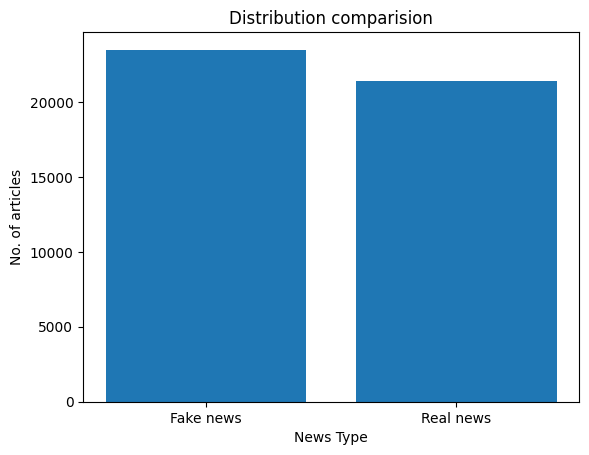

In [18]:
import matplotlib.pyplot as plt

count = {
    'Fake news' : len(fake_df),
    'Real news' : len(real_df)
}

plt.bar(count.keys(), count.values())
plt.xlabel("News Type")
plt.ylabel("No. of articles")
plt.title("Distribution comparision")
plt.show()

## Train-Test Split

In [19]:
fake_df['label'] = 0
real_df['label'] = 1

In [20]:
df = pd.concat([fake_df, real_df], ignore_index = True)

In [21]:
df.head()

,title,text,subject,date,content,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",donald trump send embarrass new year’ eve mess...,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",drunk brag trump staffer start russian collus ...,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",sheriff david clark becom internet joke threat...,0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",trump obsess even obama’ name code websit (ima...,0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",pope franci call donald trump christma speech ...,0


In [22]:
df.tail()

,title,text,subject,date,content,label
44893,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",'fulli committed' nato back new u.s. approach ...,1
44894,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",exisnexi withdrew two product chines market lo...,1
44895,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",insk cultur hub becom author minsk (reuters) -...,1
44896,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",atican upbeat possibl pope franci visit russia...,1
44897,Indonesia to buy $1.14 billion worth of Russia...,JAKARTA (Reuters) - Indonesia will buy 11 Sukh...,worldnews,"August 22, 2017",ndonesia buy $1.14 billion worth russian jet j...,1


In [23]:
X = df['content'].values
Y = df['label'].values

In [24]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, stratify = Y, random_state = 2)

In [25]:
x_train.shape

(35918,)

Tokenization

In [26]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words = 10000)
tokenizer.fit_on_texts(x_train)

In [27]:
x_train_sequence = tokenizer.texts_to_sequences(x_train)
x_test_sequence = tokenizer.texts_to_sequences(x_test)

In [28]:
x_train_sequence[0]

[4,
 11,
 874,
 294,
 94,
 2837,
 1312,
 116,
 4351,
 31,
 27,
 6,
 414,
 476,
 1504,
 116,
 1194,
 773,
 2495,
 3232,
 6372,
 727,
 783,
 399,
 11,
 874,
 29,
 94,
 128,
 6260,
 41,
 71,
 1872,
 8801,
 116,
 626,
 13,
 768,
 4392,
 410,
 773,
 4119,
 400,
 1580,
 272,
 157,
 3,
 4,
 49,
 324,
 2022,
 2299,
 695,
 768,
 11,
 336,
 1424,
 237,
 2868,
 938,
 153,
 244,
 31,
 3,
 4,
 132,
 267,
 56,
 414,
 27,
 6,
 631,
 128,
 27,
 6,
 1052,
 2837,
 2472,
 3043,
 294,
 3200,
 3232,
 276,
 83,
 195,
 3,
 4,
 132,
 267,
 3044,
 464,
 6260,
 235,
 116,
 546,
 410,
 2518,
 4971,
 2061,
 773,
 727,
 35,
 4120,
 168,
 55,
 625,
 255,
 233,
 2583,
 854,
 2022,
 6336,
 139,
 773,
 345,
 66,
 1728,
 1914,
 207,
 1,
 21,
 148,
 61,
 879,
 3092,
 2868,
 1686,
 668,
 616,
 3460,
 15,
 2338,
 109,
 24,
 336,
 521,
 5666,
 3232,
 938,
 648,
 6260,
 768,
 136,
 6117,
 3,
 4,
 276,
 2168,
 22,
 224,
 184,
 3528,
 400,
 1580,
 272,
 619,
 2100,
 128,
 1,
 2022,
 197,
 629,
 2837,
 2735,
 9206,
 29,
 557,


## Padding

In [29]:
lengths = [len(sequence) for sequence in x_train_sequence]

print("50th percentile:", np.percentile(lengths, 50))
print("75th percentile:", np.percentile(lengths, 75))
print("90th percentile:", np.percentile(lengths, 90))
print("95th percentile:", np.percentile(lengths, 95))
print("99th percentile:", np.percentile(lengths, 99))

50th percentile: 212.0
75th percentile: 298.0
90th percentile: 438.0
95th percentile: 535.0
99th percentile: 856.0


In [30]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = 600

x_train_padded = pad_sequences(
    x_train_sequence,
    maxlen = max_len,
    padding = 'post',
    truncating = 'post'
)

x_test_padded = pad_sequences(
    x_test_sequence,
    maxlen = max_len,
    padding = 'post',
    truncating = 'post'
)

In [31]:
x_train_padded.shape

(35918, 600)

In [32]:
x_test_padded.shape

(8980, 600)

## Creating the Model

In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Input

In [34]:
model = Sequential([
    Input(shape = (max_len,)),
    Embedding(10000, 128, input_length = max_len),
    LSTM(128),

    Dense(64, activation = 'relu'),
    Dropout(0.5),

    Dense(1, activation= 'sigmoid')
])

model.compile(
    loss = 'binary_crossentropy',
    optimizer = 'adam',
    metrics = ['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [35]:
model.build(input_shape = (None, max_len))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 600, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,419,905 (5.42 MB)

 Trainable params: 1,419,905 (5.42 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
y_train.shape

(35918,)

In [37]:
y_test.shape

(8980,)

In [39]:
history = model.fit(
    x_train_padded,
    y_train,
    epochs = 10,
    batch_size = 64,
    validation_split = 0.2
)

Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.5164 - loss: 0.6968 - val_accuracy: 0.5290 - val_loss: 0.6927
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.5220 - loss: 0.6863 - val_accuracy: 0.5398 - val_loss: 0.6770
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.5309 - loss: 0.6765 - val_accuracy: 0.5390 - val_loss: 0.6788
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.5324 - loss: 0.6727 - val_accuracy: 0.5394 - val_loss: 0.6771
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.6951 - loss: 0.5030 - val_accuracy: 0.9556 - val_loss: 0.1541
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.9765 - loss: 0.1123 - val_accuracy: 0.9883 - val_loss: 0.0569
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.9913 - loss: 0.0485 - val_accuracy: 0.9921 - val_loss: 0.0406
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9904 - loss: 0.0469 - 

## Model Evaluation

In [40]:
model.evaluate(x_test_padded, y_test)

281/281 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9962 - loss: 0.0146


[0.014616359956562519, 0.9962137937545776]

In [41]:
model.save('fake_news_NN.keras')

In [2]:
import sys
!{sys.executable} -m pip install --upgrade keras==3.13.2

ERROR: Could not find a version that satisfies the requirement keras==3.13.2 (from versions: 0.2.0, 0.3.0, 0.3.1, 0.3.2, 0.3.3, 1.0.0, 1.0.1, 1.0.2, 1.0.3, 1.0.4, 1.0.5, 1.0.6, 1.0.7, 1.0.8, 1.1.0, 1.1.1, 1.1.2, 1.2.0, 1.2.1, 1.2.2, 2.0.0, 2.0.1, 2.0.2, 2.0.3, 2.0.4, 2.0.5, 2.0.6, 2.0.7, 2.0.8, 2.0.9, 2.1.0, 2.1.1, 2.1.2, 2.1.3, 2.1.4, 2.1.5, 2.1.6, 2.2.0, 2.2.1, 2.2.2, 2.2.3, 2.2.4, 2.2.5, 2.3.0, 2.3.1, 2.4.0, 2.4.1, 2.4.2, 2.4.3, 2.5.0rc0, 2.6.0rc0, 2.6.0rc1, 2.6.0rc2, 2.6.0rc3, 2.6.0, 2.7.0rc0, 2.7.0rc2, 2.7.0, 2.8.0rc0, 2.8.0rc1, 2.8.0, 2.9.0rc0, 2.9.0rc1, 2.9.0rc2, 2.9.0, 2.10.0rc0, 2.10.0rc1, 2.10.0, 2.11.0rc0, 2.11.0rc1, 2.11.0rc2, 2.11.0rc3, 2.11.0, 2.12.0rc0, 2.12.0rc1, 2.12.0, 2.13.1rc0, 2.13.1rc1, 2.13.1, 2.14.0rc0, 2.14.0, 2.15.0rc0, 2.15.0rc1, 2.15.0, 3.0.0, 3.0.1, 3.0.2, 3.0.3, 3.0.4, 3.0.5, 3.1.0, 3.1.1, 3.2.0, 3.2.1, 3.3.0, 3.3.1, 3.3.2, 3.3.3, 3.4.0, 3.4.1, 3.5.0, 3.6.0, 3.7.0, 3.8.0, 3.9.0, 3.9.1, 3.9.2, 3.10.0, 3.11.0, 3.11.1, 3.11.2, 3.11.3, 3.12.0, 3.12.1, 3.12.2, 

In [3]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

TensorFlow: 2.21.0
Keras: 3.12.4
Backend: tensorflow


In [8]:
from tensorflow.keras.models import load_model

model = load_model('fake_news_NN.keras')

TypeError: <class 'keras.src.models.sequential.Sequential'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None, 'shared_object_id': 139775562227328}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 600], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer', 'optional': False}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'Embedding', 'config': {'name': 'embedding', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'input_dim': 100

281/281 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step
Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      0.99      1.00      4696
        Real       0.99      1.00      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



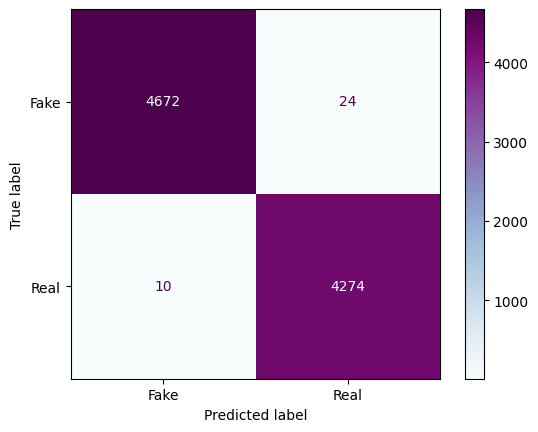

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

y_pred = model.predict(x_test_padded)
y_pred = np.round(y_pred).flatten()

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels = ['Fake', 'Real'], cmap = 'BuPu')

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names = ['Fake', 'Real']))

## Testing Performance

In [59]:
import random

In [79]:
input_index = random.randint(0, x_test.shape[0]-1)

input_data = x_test[input_index]
print(input_data)
input_seq = tokenizer.texts_to_sequences([input_data])
input_padded = pad_sequences(
    input_seq,
    maxlen = max_len,
    padding = 'post'
)

prediction = model.predict(input_padded)
prediction_class = int(prediction[0][0] >= 0.5)

if prediction_class == y_test[input_index]:
    print("Correct prediction")
else:
    print("Incorrect prediction")

print("Actual:", "Real" if y_test[input_index] == 1 else "Fake")
print("Predicted:", "Real" if prediction_class == 1 else "Fake")

ow homemad tool help north korea' missil program seoul, (reuters) - 2009, pop video north korea celebr new nation hero - one outsid expert would later realiz heart secret state ban nuclear missil programs. hero, wide avail factori across world, comput numer control (cnc) machine. big, grey boxy, cnc machin use pre-program guid produc intric part everyth automobil mobil phone furnitur clothes. offer accuraci human machin tool oper unabl achieve. north korea, thank combin homemad technolog revers engineering, machin play critic role weapon programs. allow kim jong un build nuclear bomb missil without reli heavili outsid technic aid imports. nuclear weapon expert say help acceler missil nuclear test despit intern sanction transfer sensit equipment. special section: north korea revealed. interactive: nuclear north korea interactive: kim latest act defianc north korea centrifug new missil depend compon made cnc machin tools, said jeffrey lewis, head east asia nonprolifer program middleburi 